In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, mean_absolute_error, mean_squared_error,classification_report
from sklearn.linear_model import LinearRegression


In [2]:
flood_data=pd.read_csv('flood.csv')

1. Basic Exploration

In [4]:
#Display the first 5 rows

flood_data.head(5)

,jntunh,TopographyDrainage,RiverManagement,Deforestation,Urbanization,ClimateChange,DamsQuality,Siltation,AgriculturalPractices,Encroachments,...,DrainageSystems,CoastalVulnerability,Landslides,Watersheds,DeterioratingInfrastructure,PopulationScore,WetlandLoss,InadequatePlanning,PoliticalFactors,FloodProbability
0,3,8,6,6,4,4,6,2,3,2,...,10,7,4,2,3,4,3,2,6,0.450
1,8,4,5,7,7,9,1,5,5,4,...,9,2,6,2,1,1,9,1,3,0.475
2,3,10,4,1,7,5,4,7,4,9,...,7,4,4,8,6,1,8,3,6,0.515
3,4,4,2,7,3,4,1,4,6,4,...,4,2,6,6,8,8,6,6,10,0.520
4,3,7,5,2,5,8,5,2,7,5,...,7,6,5,3,3,4,4,3,4,0.475


In [5]:
#Display the last 5 rows

flood_data.tail(5)

,jntunh,TopographyDrainage,RiverManagement,Deforestation,Urbanization,ClimateChange,DamsQuality,Siltation,AgriculturalPractices,Encroachments,...,DrainageSystems,CoastalVulnerability,Landslides,Watersheds,DeterioratingInfrastructure,PopulationScore,WetlandLoss,InadequatePlanning,PoliticalFactors,FloodProbability
49995,3,7,4,7,5,9,4,6,10,4,...,7,3,8,8,6,1,5,4,2,0.535
49996,3,10,3,8,3,3,4,4,3,11,...,8,6,3,6,4,4,2,4,5,0.510
49997,4,4,5,7,2,1,4,5,6,7,...,4,6,4,1,5,1,6,4,3,0.430
49998,4,5,4,4,6,3,10,2,6,11,...,6,3,4,7,6,2,4,0,11,0.515
49999,4,5,6,3,5,6,5,4,9,10,...,2,4,4,5,6,7,8,10,7,0.580


In [9]:
#Show the shape of the dataset
print("Shape of the dataset:",flood_data.shape)



Shape of the dataset: (50000, 21)


In [11]:
#Check the data types of all columns
flood_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 21 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   jntunh                           50000 non-null  int64  
 1   TopographyDrainage               50000 non-null  int64  
 2   RiverManagement                  50000 non-null  int64  
 3   Deforestation                    50000 non-null  int64  
 4   Urbanization                     50000 non-null  int64  
 5   ClimateChange                    50000 non-null  int64  
 6   DamsQuality                      50000 non-null  int64  
 7   Siltation                        50000 non-null  int64  
 8   AgriculturalPractices            50000 non-null  int64  
 9   Encroachments                    50000 non-null  int64  
 10  IneffectiveDisasterPreparedness  50000 non-null  int64  
 11  DrainageSystems                  50000 non-null  int64  
 12  CoastalVulnerability         

In [12]:
#Show summary statistics

flood_data.describe()

,jntunh,TopographyDrainage,RiverManagement,Deforestation,Urbanization,ClimateChange,DamsQuality,Siltation,AgriculturalPractices,Encroachments,...,DrainageSystems,CoastalVulnerability,Landslides,Watersheds,DeterioratingInfrastructure,PopulationScore,WetlandLoss,InadequatePlanning,PoliticalFactors,FloodProbability
count,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,...,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000
mean,4.991480,4.984100,5.01594,5.008480,4.989060,4.988340,5.01536,4.988600,5.006120,5.006380,...,5.006060,4.999920,4.984220,4.97982,4.988200,4.984980,5.00512,4.994360,4.990520,0.499660
std,2.236834,2.246488,2.23131,2.222743,2.243159,2.226761,2.24500,2.232642,2.234588,2.241633,...,2.238107,2.247101,2.227741,2.23219,2.231134,2.238279,2.23176,2.230011,2.246075,0.050034
min,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.00000,0.000000,0.000000,0.285000
25%,3.000000,3.000000,3.00000,3.000000,3.000000,3.000000,3.00000,3.000000,3.000000,3.000000,...,3.000000,3.000000,3.000000,3.00000,3.000000,3.000000,3.00000,3.000000,3.000000,0.465000
50%,5.000000,5.000000,5.00000,5.000000,5.000000,5.000000,5.00000,5.000000,5.000000,5.000000,...,5.000000,5.000000,5.000000,5.00000,5.000000,5.000000,5.00000,5.000000,5.000000,0.500000
75%,6.000000,6.000000,6.00000,6.000000,6.000000,6.000000,6.00000,6.000000,6.000000,6.000000,...,6.000000,6.000000,6.000000,6.00000,6.000000,6.000000,6.00000,6.000000,6.000000,0.535000
max,16.000000,18.000000,16.00000,17.000000,17.000000,17.000000,16.00000,16.000000,16.000000,18.000000,...,17.000000,17.000000,16.000000,16.00000,17.000000,19.000000,22.00000,16.000000,16.000000,0.725000


2. Data Cleaning:

In [3]:
flood_data.isnull().sum()

jntunh                             0
TopographyDrainage                 0
RiverManagement                    0
Deforestation                      0
Urbanization                       0
ClimateChange                      0
DamsQuality                        0
Siltation                          0
AgriculturalPractices              0
Encroachments                      0
IneffectiveDisasterPreparedness    0
DrainageSystems                    0
CoastalVulnerability               0
Landslides                         0
Watersheds                         0
DeterioratingInfrastructure        0
PopulationScore                    0
WetlandLoss                        0
InadequatePlanning                 0
PoliticalFactors                   0
FloodProbability                   0
dtype: int64

In [14]:
#Check for duplicate rows

flood_data[flood_data.duplicated()]

,jntunh,TopographyDrainage,RiverManagement,Deforestation,Urbanization,ClimateChange,DamsQuality,Siltation,AgriculturalPractices,Encroachments,...,DrainageSystems,CoastalVulnerability,Landslides,Watersheds,DeterioratingInfrastructure,PopulationScore,WetlandLoss,InadequatePlanning,PoliticalFactors,FloodProbability



Missing/Null Values:

Method Used: We utilized the pandas .isnull().sum() function. This method shows the number of missing (NaN or empty) entries for each column individually.

Result: The dataset contains 0 missing values across all columns. Since there are no empty gaps, no data imputation (like using fillna()) or removal was required.

Duplicate Rows:

Method Used: We used the flood_data[flood_data.duplicated()] function to identify if there are any identical, repeating rows in the dataset. Removing duplicates is critical because repetitive rows can bias a machine learning model or skew statistical insights during EDA.

Result: There are 0 duplicate rows in this dataset.



3. Data Visualization

In [15]:
flood_data.corr()

,jntunh,TopographyDrainage,RiverManagement,Deforestation,Urbanization,ClimateChange,DamsQuality,Siltation,AgriculturalPractices,Encroachments,...,DrainageSystems,CoastalVulnerability,Landslides,Watersheds,DeterioratingInfrastructure,PopulationScore,WetlandLoss,InadequatePlanning,PoliticalFactors,FloodProbability
jntunh,1.000000,-0.003470,0.002247,-0.005384,0.005092,0.005959,0.002790,-0.003191,0.002723,-0.003723,...,-0.000118,-0.004600,-0.002315,-0.008859,0.001763,-0.003597,0.005938,0.003455,0.005402,0.224081
TopographyDrainage,-0.003470,1.000000,0.002492,0.002046,0.000116,-0.002288,-0.004472,0.010675,-0.004550,-0.007272,...,-0.001608,-0.000717,-0.002040,0.005312,0.003654,0.005887,0.003515,0.005276,0.008191,0.229414
RiverManagement,0.002247,0.002492,1.000000,0.004808,-0.009651,0.007199,0.007697,-0.000389,0.003635,0.009253,...,0.002171,-0.000111,-0.004339,0.000097,0.000604,-0.001382,0.002012,0.000364,-0.006323,0.228917
Deforestation,-0.005384,0.002046,0.004808,1.000000,-0.011325,0.000517,-0.000728,-0.000823,0.002929,-0.003507,...,-0.001060,-0.003019,0.005258,0.002171,-0.002093,0.000138,-0.000718,-0.001108,0.001242,0.220237
Urbanization,0.005092,0.000116,-0.009651,-0.011325,1.000000,0.007478,0.000268,-0.001287,-0.001391,-0.011386,...,-0.005281,-0.000881,-0.000651,-0.003479,0.004222,0.002154,0.013263,-0.000864,-0.002418,0.220867
ClimateChange,0.005959,-0.002288,0.007199,0.000517,0.007478,1.000000,-0.002889,0.001514,-0.003362,0.000075,...,-0.007587,-0.001467,0.000689,0.003023,0.003281,-0.008334,-0.000547,-0.000186,-0.004453,0.220986
DamsQuality,0.002790,-0.004472,0.007697,-0.000728,0.000268,-0.002889,1.000000,0.003239,0.001743,0.001638,...,0.004165,-0.009503,0.000436,0.005322,-0.004001,0.006856,-0.000662,0.001535,0.001699,0.227467
Siltation,-0.003191,0.010675,-0.000389,-0.000823,-0.001287,0.001514,0.003239,1.000000,-0.003911,0.000158,...,-0.008296,-0.003564,-0.001866,0.003682,0.003045,-0.002484,0.007903,0.011918,-0.001597,0.226544
AgriculturalPractices,0.002723,-0.004550,0.003635,0.002929,-0.001391,-0.003362,0.001743,-0.003911,1.000000,-0.006564,...,0.000648,-0.003708,0.004142,0.004371,0.003248,0.001678,-0.007963,-0.002221,-0.001280,0.221846
Encroachments,-0.003723,-0.007272,0.009253,-0.003507,-0.011386,0.000075,0.001638,0.000158,-0.006564,1.000000,...,-0.005960,-0.006591,-0.003032,0.003679,0.002774,0.003874,0.005706,0.001380,-0.007547,0.218259


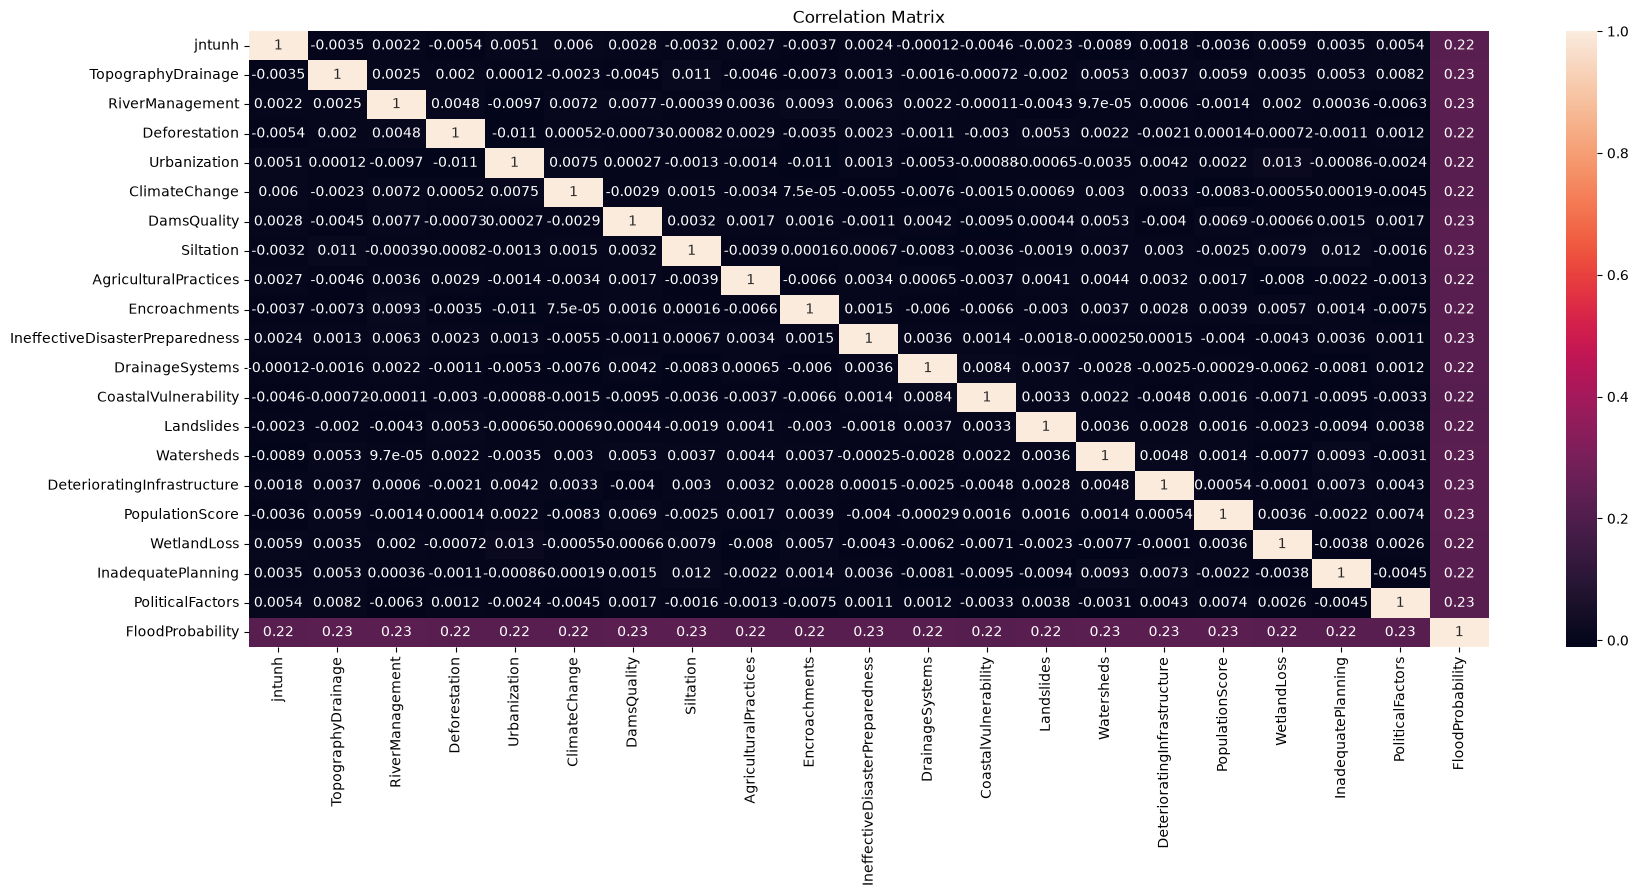

In [18]:
#Correlation matrix (heatmap)

plt.figure(figsize=(20,8))
sns.heatmap(flood_data.corr(),annot=True)
plt.title("Correlation Matrix")
plt.show()

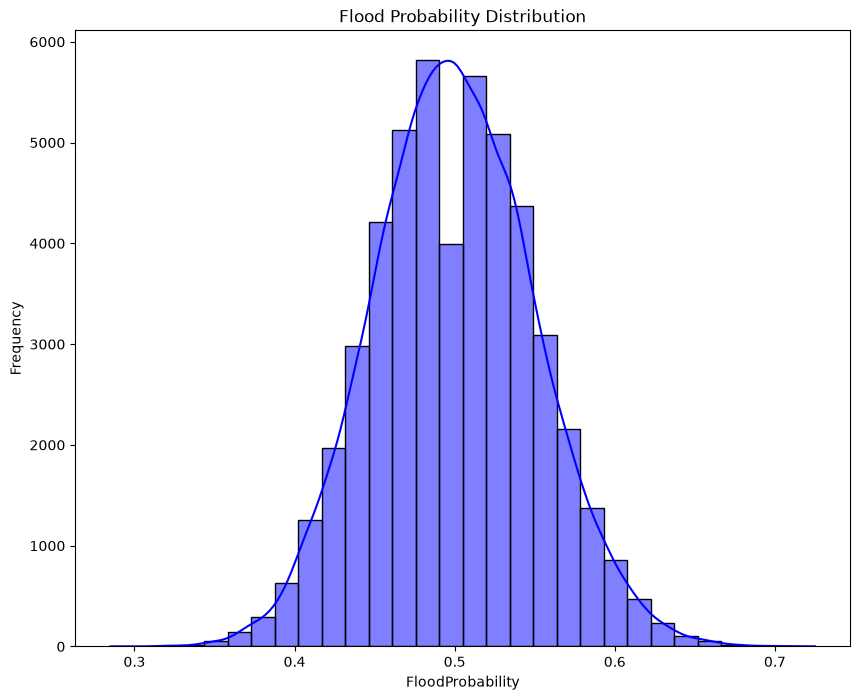

In [26]:
#Histogram of the dataset

plt.figure(figsize=(10,8))
sns.histplot(flood_data['FloodProbability'],bins=30,color='blue', kde=True)
plt.title('Flood Probability Distribution')
plt.xlabel('FloodProbability')
plt.ylabel('Frequency')
plt.show()

The FloodProbability histogram demonstrates a balanced, bell-shaped normal distribution centered precisely at a mean and median of 0.50. The data ranges from a minimum probability of 0.28 to a maximum of 0.73, with most values concentrated in the moderate range between 0.465 and 0.535. The absence of significant skewness or extreme outliers confirms that the target variable is well-behaved and ready for standard parametric machine learning models without requiring target transformations.

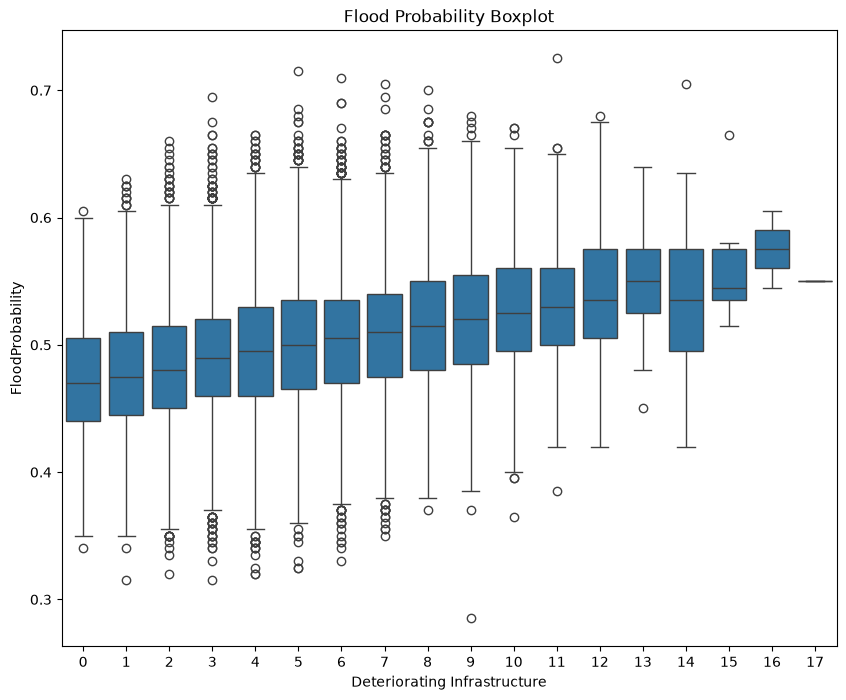

In [ ]:
#Boxplot of the dataset DeterioratingInfrastructure vs FloodProbability

plt.figure(figsize=(10,8))
sns.boxplot(x=flood_data['DeterioratingInfrastructure'],y=flood_data['FloodProbability'])
plt.title('Flood Probability Boxplot')
plt.xlabel('Deteriorating Infrastructure')
plt.ylabel('FloodProbability')
plt.show()

The boxplot illustrates a consistent positive linear trend between Deteriorating Infrastructure scores and FloodProbability. As the infrastructure deterioration score increases from 0 to 16, the median flood probability steadily rises from approximately 0.47 to 0.58, demonstrating a direct risk progression. The uniform Interquartile Ranges (IQR) across categories combined with symmetric outlier distributions further confirm that higher infrastructure degradation consistently elevates the baseline likelihood of flooding.

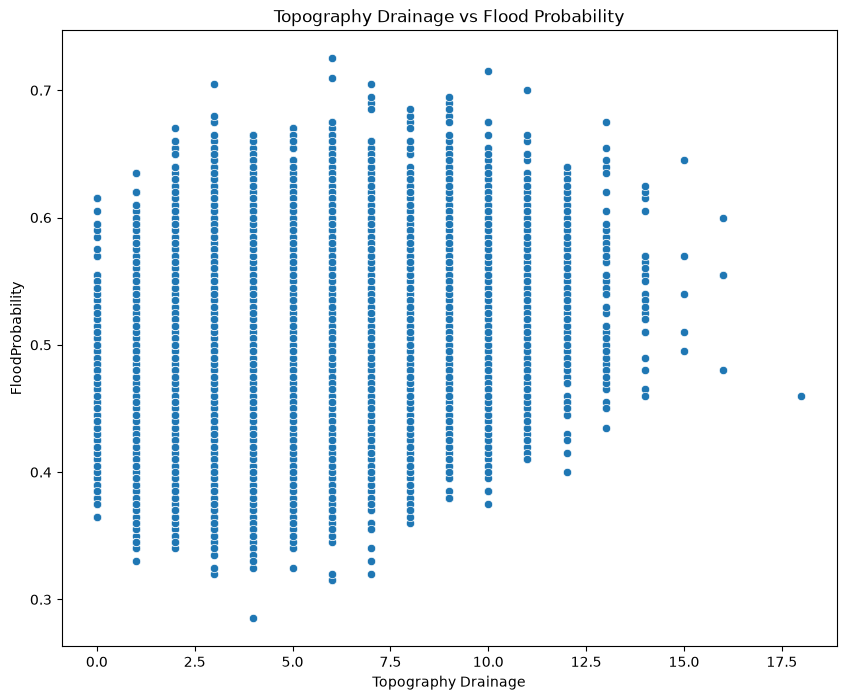

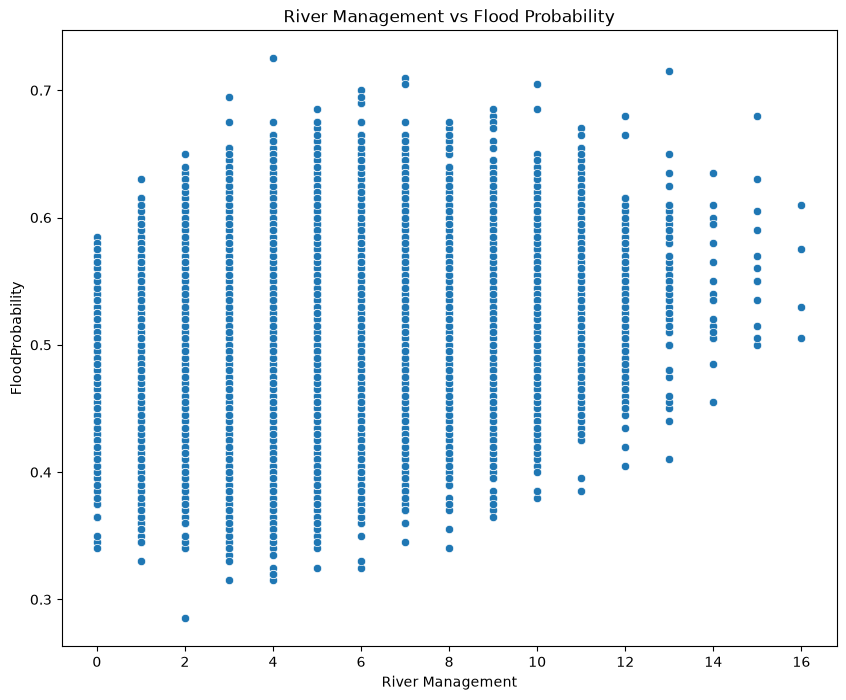

In [31]:
#Scatter plot of the dataset TopographyDrainage vs FloodProbability

plt.figure(figsize=(10,8))
sns.scatterplot(x=flood_data['TopographyDrainage'],y=flood_data['FloodProbability'])
plt.title('Topography Drainage vs Flood Probability')               
plt.xlabel('Topography Drainage')
plt.ylabel('FloodProbability')
plt.show()

plt.figure(figsize=(10,8))
sns.scatterplot(x=flood_data['RiverManagement'],y=flood_data['FloodProbability'])
plt.title('River Management vs Flood Probability')               
plt.xlabel('River Management')
plt.ylabel('FloodProbability')
plt.show()

The scatter plots illustrate a positive relationship between input features (Topography Drainage & River Management) and the target variable FloodProbability. As the scores for poor topography drainage and river management deficiencies increase, the lower and upper bounds of flood probability shift upward. This overall upward progression confirms that poor geographic drainage capacity and inadequate river management directly increase the likelihood of flooding.

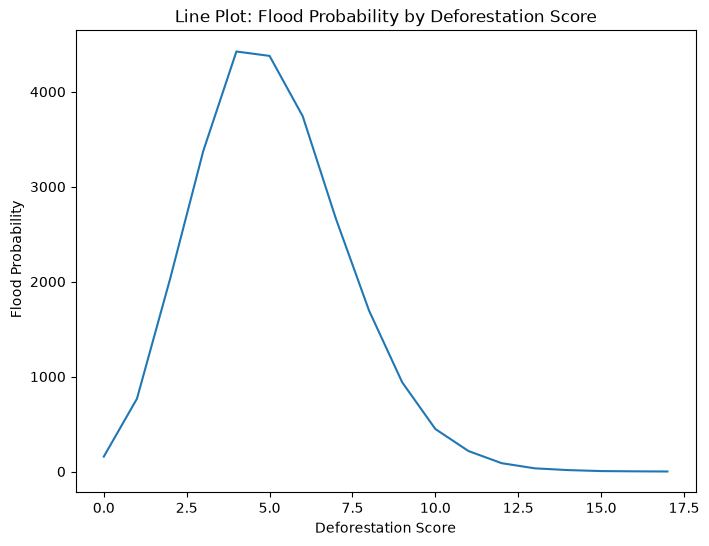

In [33]:
#Line Plot of Deforestation Score vs Flood Probability

plt.figure(figsize=(8, 6))
flood_data.groupby('Deforestation')['FloodProbability'].sum().plot()
plt.title('Line Plot: Flood Probability by Deforestation Score')
plt.xlabel('Deforestation Score')
plt.ylabel(' Flood Probability')
plt.show()

The line plot depicts a bell-shaped distribution of record counts across different Deforestation Score values relative to flood probability analysis. The dataset frequency peaks around deforestation scores of 4 to 5, exceeding 4,000 observations, while extreme scores (below 1 or above 10) are relatively rare. This approximately normal distribution confirms that most recorded instances in the dataset represent moderate deforestation levels rather than extreme conditions.

Data Processing

In [4]:
df=flood_data.copy()
df.drop(columns=['jntunh'],inplace=True)

df

,TopographyDrainage,RiverManagement,Deforestation,Urbanization,ClimateChange,DamsQuality,Siltation,AgriculturalPractices,Encroachments,IneffectiveDisasterPreparedness,DrainageSystems,CoastalVulnerability,Landslides,Watersheds,DeterioratingInfrastructure,PopulationScore,WetlandLoss,InadequatePlanning,PoliticalFactors,FloodProbability
0,8,6,6,4,4,6,2,3,2,5,10,7,4,2,3,4,3,2,6,0.450
1,4,5,7,7,9,1,5,5,4,6,9,2,6,2,1,1,9,1,3,0.475
2,10,4,1,7,5,4,7,4,9,2,7,4,4,8,6,1,8,3,6,0.515
3,4,2,7,3,4,1,4,6,4,9,4,2,6,6,8,8,6,6,10,0.520
4,7,5,2,5,8,5,2,7,5,7,7,6,5,3,3,4,4,3,4,0.475
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,7,4,7,5,9,4,6,10,4,4,7,3,8,8,6,1,5,4,2,0.535
49996,10,3,8,3,3,4,4,3,11,8,8,6,3,6,4,4,2,4,5,0.510
49997,4,5,7,2,1,4,5,6,7,7,4,6,4,1,5,1,6,4,3,0.430
49998,5,4,4,6,3,10,2,6,11,5,6,3,4,7,6,2,4,0,11,0.515


In [5]:
duplicate = df[df.duplicated()]
duplicate

,TopographyDrainage,RiverManagement,Deforestation,Urbanization,ClimateChange,DamsQuality,Siltation,AgriculturalPractices,Encroachments,IneffectiveDisasterPreparedness,DrainageSystems,CoastalVulnerability,Landslides,Watersheds,DeterioratingInfrastructure,PopulationScore,WetlandLoss,InadequatePlanning,PoliticalFactors,FloodProbability


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 20 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   TopographyDrainage               50000 non-null  int64  
 1   RiverManagement                  50000 non-null  int64  
 2   Deforestation                    50000 non-null  int64  
 3   Urbanization                     50000 non-null  int64  
 4   ClimateChange                    50000 non-null  int64  
 5   DamsQuality                      50000 non-null  int64  
 6   Siltation                        50000 non-null  int64  
 7   AgriculturalPractices            50000 non-null  int64  
 8   Encroachments                    50000 non-null  int64  
 9   IneffectiveDisasterPreparedness  50000 non-null  int64  
 10  DrainageSystems                  50000 non-null  int64  
 11  CoastalVulnerability             50000 non-null  int64  
 12  Landslides                   

In [7]:
x = df.drop(columns = ['FloodProbability'])
y = df['FloodProbability']


In [11]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print(x_train)
print(y_train)
print(x_test)
print(y_test)

       TopographyDrainage  RiverManagement  Deforestation  Urbanization  \
39087                   3                6              2             7   
30893                   5                6              5             4   
45278                   3                4              5             8   
16398                   4                5              6             2   
13653                   5                5              3             2   
...                   ...              ...            ...           ...   
11284                   5                7              9             3   
44732                   4                5              6             4   
38158                   8                2              2             2   
860                     6                3              5            10   
15795                  10                8              3             6   

       ClimateChange  DamsQuality  Siltation  AgriculturalPractices  \
39087              4        

In [12]:
lr = LinearRegression()
lr.fit(x_train, y_train)
lr_pred = lr.predict(x_test)

In [13]:
lr_pred

array([0.4450849 , 0.49968249, 0.48490783, ..., 0.49482384, 0.62029632,
       0.43506737], shape=(10000,))

In [14]:
lr_mae = mean_absolute_error(y_test, lr_pred)
lr_mse = mean_squared_error(y_test, lr_pred)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))

print('MAE Linear Regression: ', lr_mae)
print('MSE Linear Regression: ', lr_mse)
print('RMSE Linear Regression: ', lr_rmse)

MAE Linear Regression:  0.008813090567593964
MSE Linear Regression:  0.00012620768688380893
RMSE Linear Regression:  0.011234219460372355
